# Практическая работа №7. От тензоров PyTorch к классификации изображений

**Дицель Н.С., ИКБО-11-23.** 07.11.2026. Проверил: ст. преподаватель Приходько Н.А.

**Цель:** проверить вычисления PyTorch, обучить классификаторы MNIST, BloodMNIST и CIFAR-10. **Окружение:** Python 3.12.10, PyTorch 2.15.0+cpu, torchvision 0.29.2+cpu, cpu, 2 потока CPU. Seed=42, Adam(lr=0,001), batch=128, пять эпох. Test не используется для выбора архитектуры или эпохи.

## 1. Тензоры и шаг обучения

- Проверены арифметика, индексация, broadcasting, reshape/permute и общая память from_numpy.
- Ручное XWᵀ+b совпало с Linear; Linear(3,2) содержит 3×2+2=8 параметров.
- Два слоя без активации сведены в один. ReLU позволила аппроксимировать x².
- Ручные градиенты MSE и шаг SGD совпали с PyTorch; потеря уменьшилась.
- CrossEntropyLoss совпала с ручным расчётом; на вход подаются логиты.
- Проверены ручная свёртка и BatchNorm в train/eval. Pooling обучаемых весов не имеет.

**Вывод:** формы и режим вычисления важны отдельно от значений. zero_grad очищает градиенты, backward вычисляет их, step обновляет веса. Dataset возвращает один объект; DataLoader формирует пакеты.

## 2. MNIST: линейная модель

Использованы 10 000 train и 2 000 valid из исходного train; проверено отсутствие общих индексов. Официальный test — 10 000 изображений. Модель Flatten → Linear(784,10), **7850 параметров**.

После пятой эпохи: **accuracy test 89.87%**, **macro-F1 0.8975**. Потеря train изменилась с 1.3562 до 0.4253; accuracy valid — с 83.90% до 89.40%.

**Вывод:** линейное правило по пикселям уже различает большинство цифр, но не строит локальные признаки. Веса выхода «3» визуализированы в блокноте; это вклад пикселя в логит, а не вероятность.

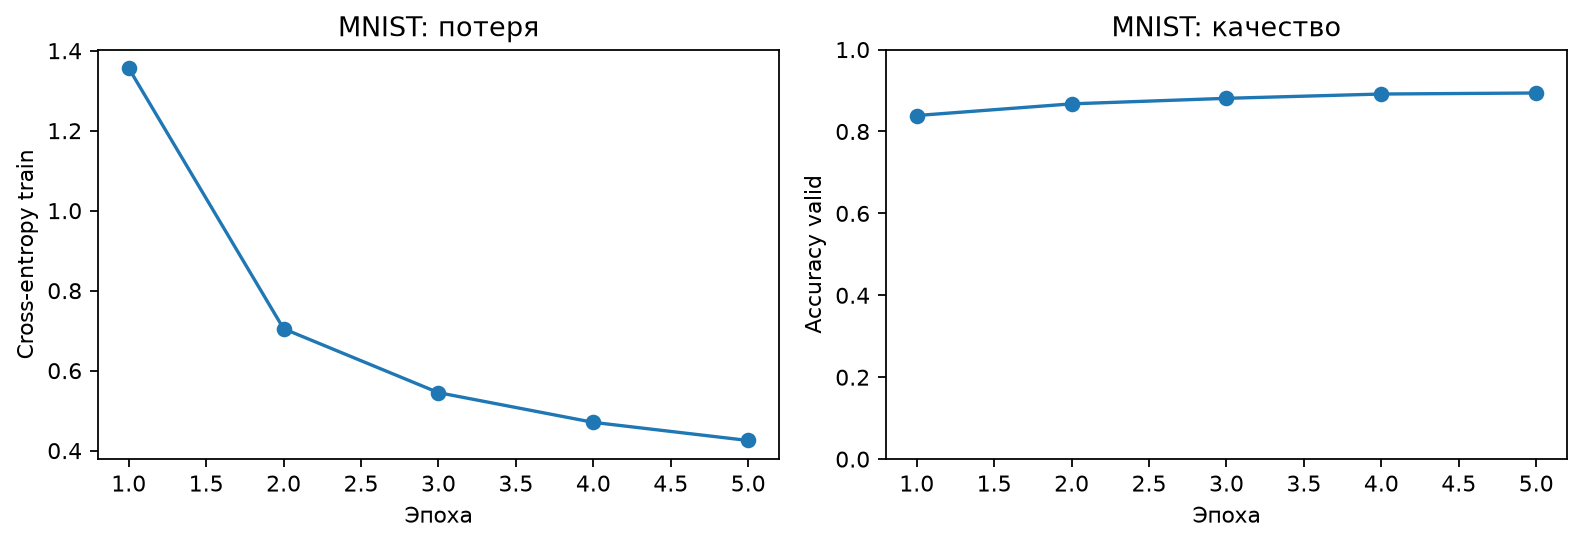

## 3. BloodMNIST: линейная модель и CNN

Общий train: по 600 изображений восьми классов, всего 4 800. Официальные valid — 1 712 и test — 3 421 сохранены целиком. Обе модели используют RGB 28×28 и одинаковую нормировку, порядок train-пакетов и число эпох.

CNN: Conv(3→8) → BN → ReLU → Pool → Conv(8→16) → BN → ReLU → Pool → Flatten → Linear(784→8). Проверено совпадение ответа через вектор признаков с полным проходом.

| Модель | Accuracy test | Macro-F1 test | Параметров | Обучение 5 эпох, с | Пакет 64, мс |
| --- | --- | --- | --- | --- | --- |
| Линейная | 0.7357 | 0.7101 | 18824 | 5.4983 | 0.1718 |
| CNN | 0.8468 | 0.8287 | 7696 | 10.5268 | 6.7133 |

**Вывод:** CNN увеличила accuracy на 11.11 п.п. при меньшем числе параметров (7696 против 18824). На этом CPU пакет 64 CNN обрабатывает в 39.1 раза дольше: свёртки выполняют много операций над картами.

Время — медиана трёх повторов после прогрева; чтение и перенос данных исключены. Чаще всего CNN ошибалась в направлении **Незрелые гранулоциты → Базофил (90 объектов)**. Число параметров, качество и скорость нужно оценивать отдельно.

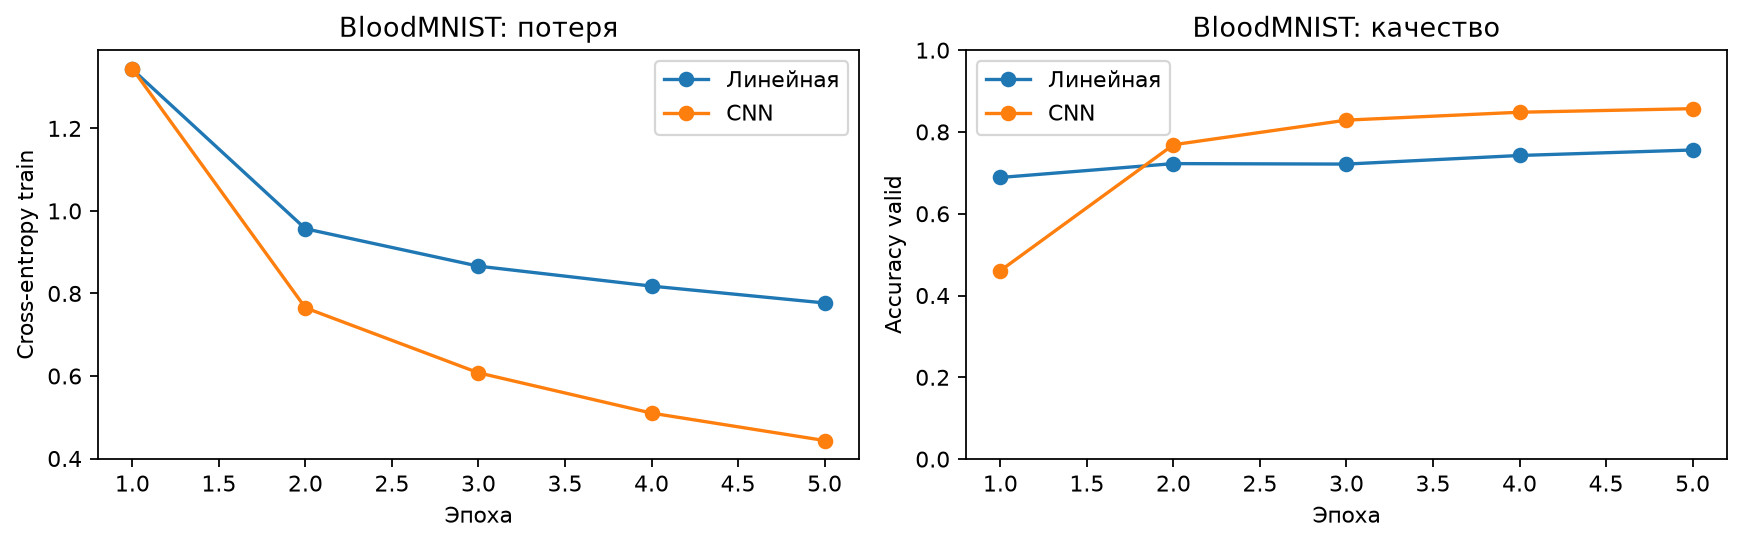

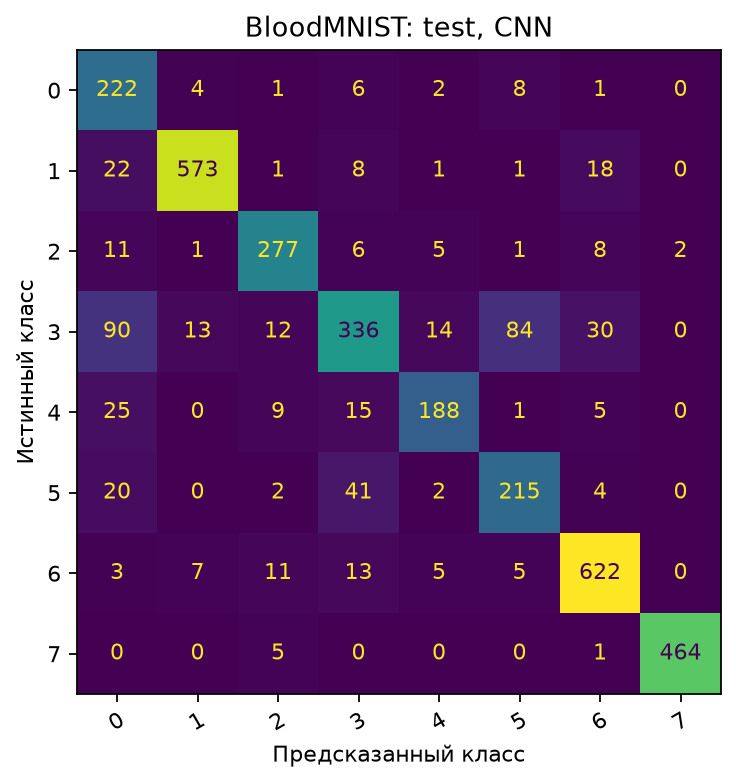

## 4. Самостоятельная часть: CIFAR-10, вариант №1

Выбраны **самолёт, автомобиль, корабль**; исходные коды [0, 1, 8] заменены на 0,1,2 в том же порядке. Правило назначения по группе/зачётке в материалах отсутствует; использован вариант №1 из заготовки.

Состав: **4 500 train / 900 valid / 900 test**. На класс — 1 500/300/300; train и valid взяты из исходного train без пересечения, test — из официального test. Индексы сохранены. Ошибочные упоминания 100 test в заготовке заменены требованием методички — 300.

Предобработка: Resize 32→28, ToTensor, Normalize(mean=0,5; std=0,5) по каналам, однократно. Пакет — (N,3,28,28), метки int64. CNN: два блока 3→8→16, pooling до 7×7, Flatten 784, Linear на три логита; **3771 параметр**.

| epoch | train_loss | valid_accuracy | train_seconds |
| --- | --- | --- | --- |
| 1 | 0.8315 | 0.5156 | 2.2118 |
| 2 | 0.6474 | 0.7100 | 2.1639 |
| 3 | 0.6160 | 0.7267 | 2.1571 |
| 4 | 0.5580 | 0.7511 | 2.1833 |
| 5 | 0.5283 | 0.7600 | 2.1816 |

Параметры пятой эпохи: **accuracy test 77.44%**, **macro-F1 0.7746**. Постоянный ответ на сбалансированном test даёт 33,33%. Самый большой прирост valid между эпохами — **1→2: 19.44 п.п.**

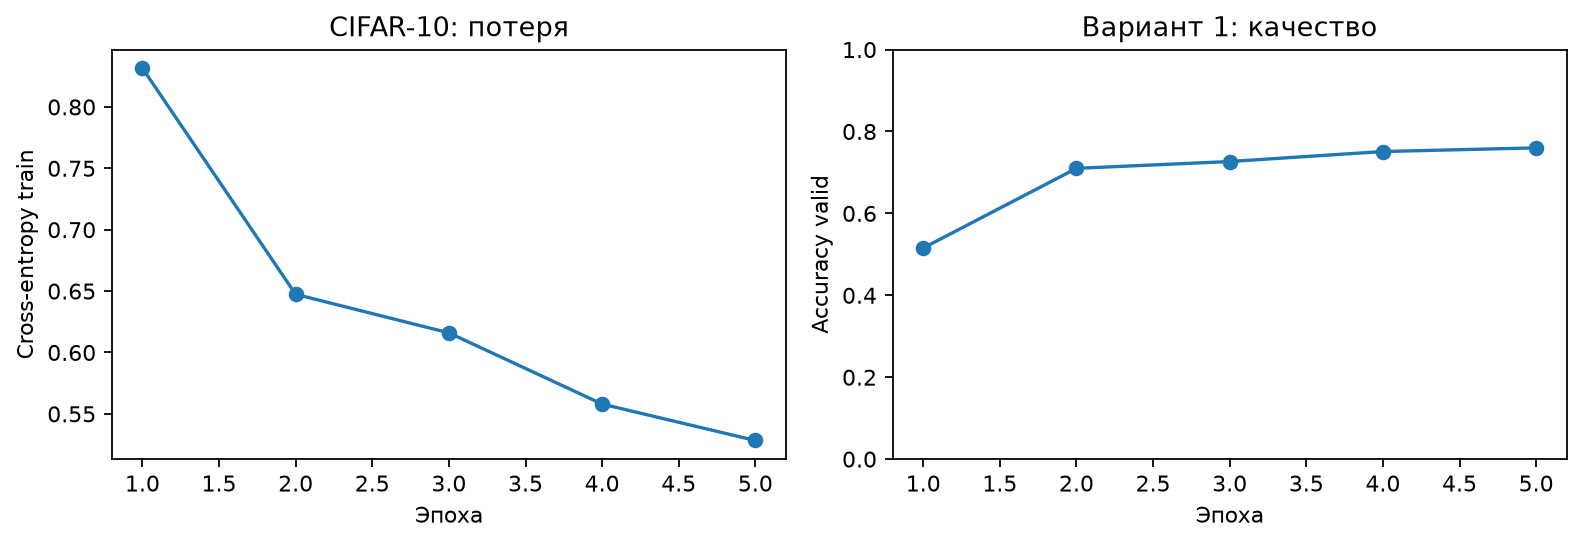

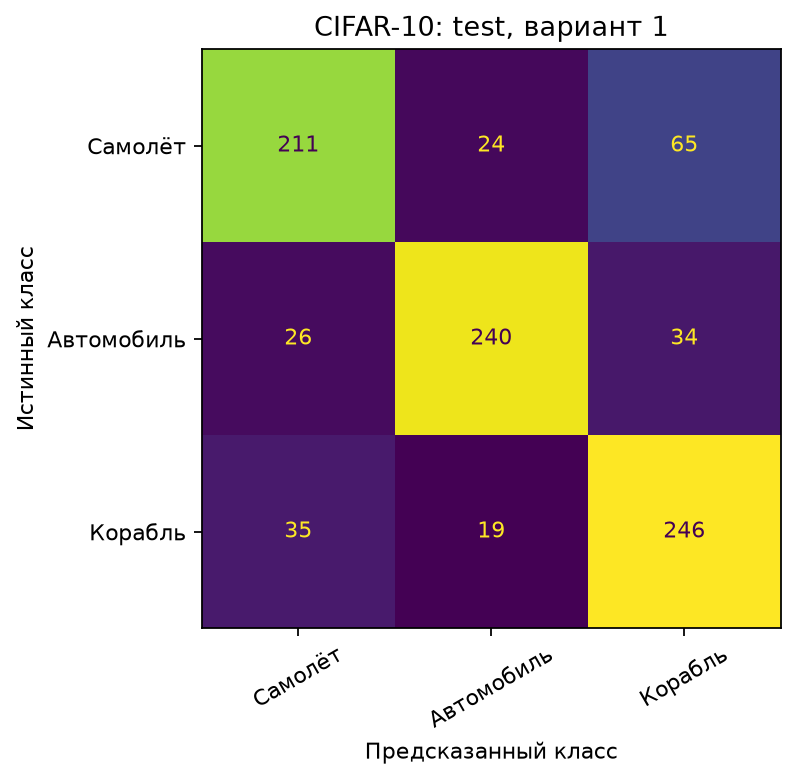

**Ошибки:** наиболее частое направление — **Самолёт → Корабль (65 объектов)**. Ниже показаны первые три неверных ответа, без отбора по красивому примеру. Подпись содержит исходный класс и предсказание; для показа нормировка обращена image×0,5+0,5.

Малая модель обучалась только пять эпох на части корпуса; результат относится к этому разбиению. График valid описывает процесс обучения, итоговый test не использовался для подбора.

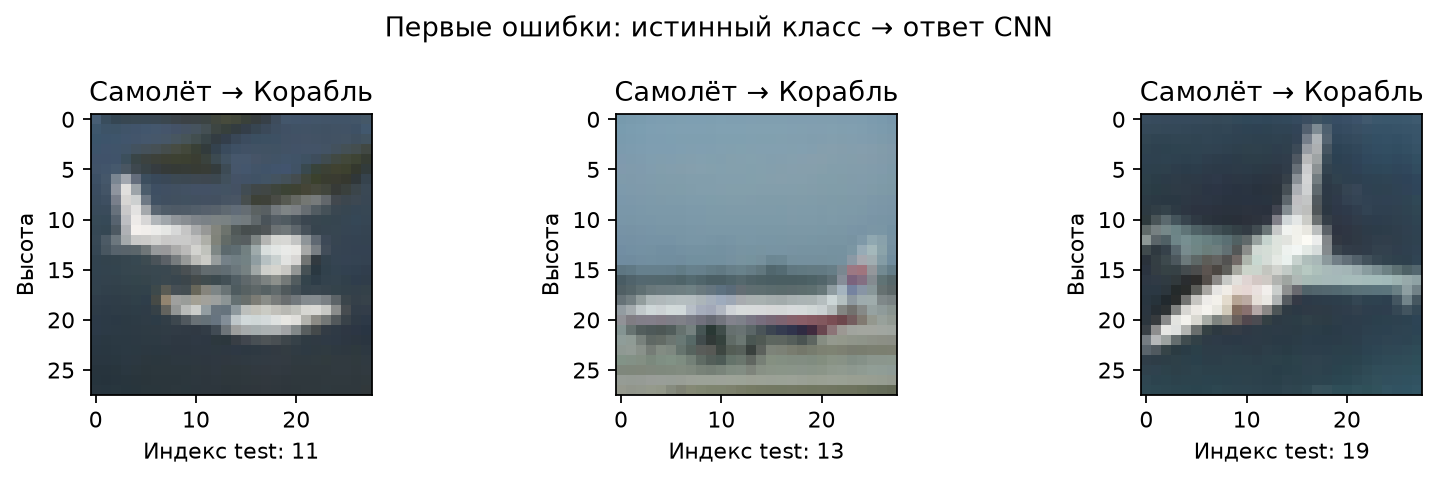

**Сохранено:** выполненный блокнот, четыре state_dict, истории, метрики по классам, прогнозы, индексы разбиений, параметры опыта и рисунки. Для CIFAR-10 после загрузки весов логиты на 16 фиксированных test-примерах совпали. В проходах оценки веса и буферы BatchNorm не менялись.

**Ответы на вопросы:** отдельный файл «Ответы_на_вопросы_7.md» — 15 полных вопросов лекции №7 (слайды 70–71) и 7 вопросов раздела 8 практики, с краткими ответами.

Источники: выданные методичка и лекция №7; [PyTorch](https://pytorch.org/get-started/locally/), [MedMNIST](https://medmnist.com/), [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html).
